<b>ML Experiment 3: Implementation of Logistic Regression</b><br><br><b>Aim:</b> Classify Wisconsin Breast Cancer tumors via a standardized Logistic Regression pipeline, inspect probability thresholds, log-loss, and the Precision-Recall curve.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    log_loss,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

In [2]:
dataset = load_breast_cancer(as_frame=True)
features = dataset.data
targets = dataset.target

x_tr, x_te, y_tr, y_te = train_test_split(
    features, targets, test_size=0.25, stratify=targets, random_state=31
)

logit_pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=0.8, solver="lbfgs", max_iter=1500, random_state=31),
)
logit_pipe.fit(x_tr, y_tr)

prob_pos = logit_pipe.predict_proba(x_te)[:, 1]
pred_default = (prob_pos >= 0.5).astype(int)

In [3]:
print("Threshold Sensitivity Analysis:")
for th in [0.40, 0.50, 0.60]:
    pred_th = (prob_pos >= th).astype(int)
    print(f"Threshold {th:.2f} -> Accuracy: {accuracy_score(y_te, pred_th):.4f}")

print(f"\nLog-Loss: {log_loss(y_te, prob_pos):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_te, prob_pos):.4f}")
print("\nClassification Report (Threshold = 0.50):")
print(classification_report(y_te, pred_default, target_names=dataset.target_names))

prec_curve, rec_curve, _ = precision_recall_curve(y_te, prob_pos)
ap_score = average_precision_score(y_te, prob_pos)
cmat = confusion_matrix(y_te, pred_default)

Threshold Sensitivity Analysis:
Threshold 0.40 -> Accuracy: 0.9650
Threshold 0.50 -> Accuracy: 0.9790
Threshold 0.60 -> Accuracy: 0.9510

Log-Loss: 0.0970
ROC-AUC:  0.9945

Classification Report (Threshold = 0.50):
              precision    recall  f1-score   support

   malignant       1.00      0.94      0.97        53
      benign       0.97      1.00      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.97      0.98       143
weighted avg       0.98      0.98      0.98       143



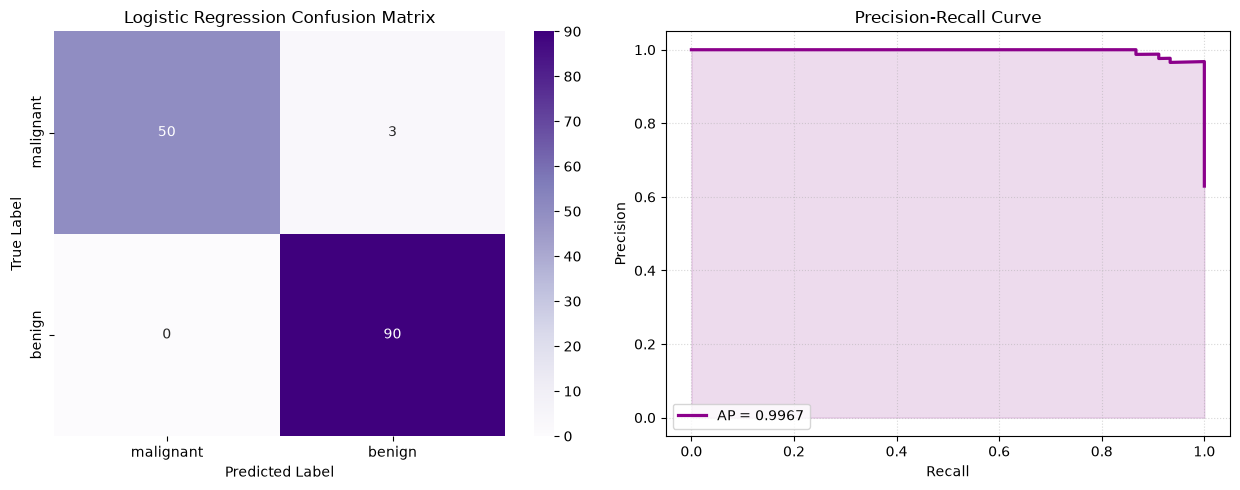

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5))

sns.heatmap(
    cmat,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=dataset.target_names,
    yticklabels=dataset.target_names,
    ax=ax[0],
)
ax[0].set_title("Logistic Regression Confusion Matrix")
ax[0].set_xlabel("Predicted Label")
ax[0].set_ylabel("True Label")

ax[1].plot(rec_curve, prec_curve, color="darkmagenta", linewidth=2.3, label=f"AP = {ap_score:.4f}")
ax[1].fill_between(rec_curve, prec_curve, alpha=0.14, color="purple")
ax[1].set_title("Precision-Recall Curve")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].legend(loc="lower left")
ax[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

<b>Observation:</b> Standardized Logistic Regression yields low log-loss, strong ROC-AUC, and high Average Precision across threshold choices.